# Figure 2. FastRNA performance and agreement with established annotation tools

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.ticker import FixedLocator, FuncFormatter

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREY, GRAY_LIGHT = "#4C72B0", "#DD8452", "0.55", "0.72"
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.028, dy=0.022):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

CWW_CANON_SEQS = {"GC", "CG", "AU", "UA"}
NONCWW_ORDER = ["tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
CLASS_ORDER = ["cWW (canon)", "cWW (non-canon)", *NONCWW_ORDER]

def _canon_lw(lw):
    if not lw or len(lw) < 3:
        return lw
    o = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if o.get(lw[1], 0) > o.get(lw[2], 0) else lw

def _n_dssr_dotted(diffs):
    n = 0
    for d in diffs:
        if d["source"] != "python_only":
            continue
        r = d.get("reason") or ""
        if (r.startswith("dssr_assigns:") and "." in r.split(":", 1)[1]) \
                or "." in (d.get("dssr_lw_class") or ""):
            n += 1
    return n

def _cww_split_metrics(cww_data, canonical):
    s, diffs = cww_data["summary"], cww_data["differences"]
    keep = (lambda q: q in CWW_CANON_SEQS) if canonical else (lambda q: q not in CWW_CANON_SEQS)
    matched = sum(v for k, v in s["matched_by_sequence"].items() if keep(k))
    dssr_only = [d for d in diffs if d["source"] == "dssr_only" and keep(d["sequence"])]
    py_only = [d for d in diffs if d["source"] == "python_only" and keep(d["sequence"])]
    total_dssr, total_python = matched + len(dssr_only), matched + len(py_only)
    cc = matched
    for d in dssr_only:
        r = d["reason"] or ""
        if r == "not_selected":
            cc += 1
        elif r.startswith("python_assigns:"):
            a = r.split(":", 1)[1]
            if "|" in a and "cWW" in [_canon_lw(p) for p in a.split("|")]:
                cc += 1
    mis = sum(1 for d in py_only if (d["reason"] or "").startswith("dssr_assigns:")
              and "." not in d["reason"].split(":", 1)[1]
              and _canon_lw(d["reason"].split(":", 1)[1]) != "cWW")
    return {"recall_cls": cc / total_dssr if total_dssr else 0,
            "prec_cls": cc / (cc + mis) if (cc + mis) else 0,
            "total_dssr": total_dssr, "total_python": total_python, "matched": matched}

def build_metrics():
    cww = _json("comparison/cWW.json")
    metrics = {"cWW (canon)": _cww_split_metrics(cww, True),
               "cWW (non-canon)": _cww_split_metrics(cww, False)}
    for lw in NONCWW_ORDER:
        d = _json(f"comparison/{lw}.json")
        s = d.get("summary", d)
        cc, mis = s["classified_correct"], s["classified_misclassified"]
        mis_f = mis - _n_dssr_dotted(d["differences"])
        metrics[lw] = {"recall_cls": s["classified_recall"],
                       "prec_cls": cc / (cc + mis_f) if (cc + mis_f) else 0,
                       "total_dssr": s["total_dssr_pairs"],
                       "total_python": s["total_python_pairs"], "matched": s["matched"]}
    return metrics

METRICS = build_metrics()
FAMILY_ORDER = sorted(NONCWW_ORDER, key=lambda c: -METRICS[c]["recall_cls"])

def runtime():
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    return df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()

print(f"{ROOT.name}: {len(METRICS)} LW rows, {len(runtime()):,} timed structures")

SOURCE_DATA = ROOT / "figures" / "source_data"
SOURCE_DATA.mkdir(parents=True, exist_ok=True)
pd.DataFrame(METRICS).T.rename_axis("family").to_csv(SOURCE_DATA / "figure2_class_metrics.csv")

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


PARSE-RNA-Analysis: 13 LW rows, 2,096 timed structures


## Panel D
Recall and precision relative to DSSR across Leontis-Westhof classes


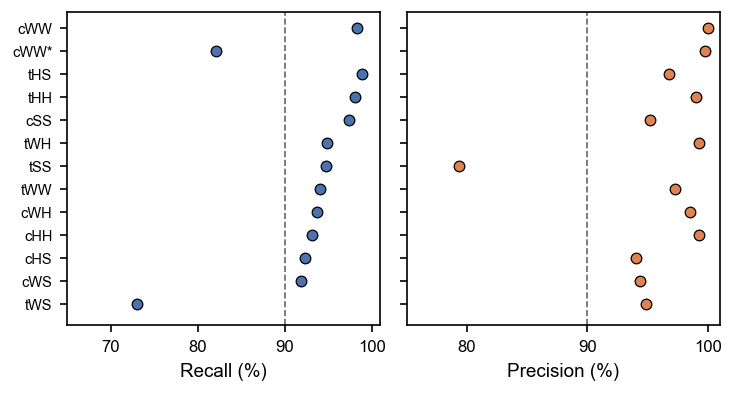

In [2]:
def _row_positions(n):
    return np.arange(n - 1, -1, -1, dtype=float)

A_CLASSES = ["cWW (canon)", "cWW (non-canon)", *FAMILY_ORDER]
A_LABELS = ["cWW", "cWW*", *FAMILY_ORDER]

def draw_recall_precision(ax_r, ax_p):
    y = _row_positions(len(A_CLASSES))
    recall = np.array([METRICS[c]["recall_cls"] * 100 for c in A_CLASSES])
    prec = np.array([METRICS[c]["prec_cls"] * 100 for c in A_CLASSES])
    for ax, vals, color, name, lo in ((ax_r, recall, BLUE, "Recall", 65),
                                      (ax_p, prec, ORANGE, "Precision", 75)):
        ax.axvline(90, color="0.4", ls="--", lw=0.8, zorder=0)
        ax.scatter(vals, y, s=26, color=color, zorder=3, edgecolors="black", linewidths=0.6)
        ax.set_xlim(lo, 101)
        ax.set_xticks([t for t in (70, 80, 90, 100) if t >= lo])
        ax.set_xlabel(f"{name} (%)")
        ax.set_ylim(y.min() - 0.9, y.max() + 0.7)
        ax.set_yticks(y)
        finish(ax)
        ax.set_box_aspect(1)
    ax_r.set_yticklabels(A_LABELS, fontsize=7)
    ax_p.tick_params(labelleft=False)

fig, axes = plt.subplots(1, 2, figsize=(5.0, 3.2))
draw_recall_precision(*axes)
fig.tight_layout(w_pad=0.7)
save(fig, "figures/main/figure2_A_recall_precision.png")
plt.show()


## Shared tool-comparison helpers


In [3]:
from collections import Counter
from functools import lru_cache

def draw_split_bars(ax, values, ci, xlabel):
    values = values.reindex(TOOL_ORDER)
    y = np.arange(len(TOOL_ORDER))
    height, gap = 0.31, 0.12
    for offset, kind, color, name in ((-(height + gap) / 2, "canonical", ORANGE, "Canonical"),
                                      ((height + gap) / 2, "non-canonical", BLUE, "Non-canonical")):
        v = values[kind].to_numpy(float)
        ax.barh(y + offset, v, height, color=color, label=name,
                edgecolor="black", linewidth=0.6)
    ax.set_yticks(y, TOOL_ORDER)
    ax.set_ylim(len(TOOL_ORDER) - 0.4, -0.6)
    ax.set_xlim(0, 1.06)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel(xlabel)
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2,
              handlelength=1.0, handletextpad=0.3, columnspacing=1.4,
              borderaxespad=0.0, borderpad=0.0)
    finish(ax)


def equalize_pair_gaps(ax, dpi=150):
    import math
    fig = ax.figure
    fig.canvas.draw()
    bars = [b for b in ax.patches if b.get_width() > 0 and b.get_height() > 0]
    horizontal = bars[0].get_height() < bars[0].get_width() or ax.get_xlim()[1] <= 1.1
    k = 1 if horizontal else 0
    to_px = lambda v: ax.transData.transform((0, v) if k else (v, 0))[k] * dpi / fig.dpi
    to_data = lambda px: ax.transData.inverted().transform(
        (0, px * fig.dpi / dpi) if k else (px * fig.dpi / dpi, 0))[k]
    start = (lambda b: b.get_y()) if k else (lambda b: b.get_x())
    size = (lambda b: b.get_height()) if k else (lambda b: b.get_width())

    def span(b):
        a, c = to_px(start(b)), to_px(start(b) + size(b))
        return min(a, c), max(a, c)

    bars.sort(key=lambda b: span(b)[0])
    (a0, a1), (b0, _) = span(bars[0]), span(bars[1])
    w_px, g_px = round(a1 - a0), math.floor(b0 - a1)
    for first, second in zip(bars[0::2], bars[1::2]):
        p0 = round(span(first)[0])
        for bar, lo in ((first, p0), (second, p0 + w_px + g_px)):
            d0, d1 = to_data(lo), to_data(lo + w_px)
            if k:
                bar.set_y(min(d0, d1)); bar.set_height(abs(d1 - d0))
            else:
                bar.set_x(min(d0, d1)); bar.set_width(abs(d1 - d0))


def seat_legend(ax, gap_pt=0.2):
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    leg = ax.get_legend()
    lowest = min(h.get_window_extent(r).y0 for h in [*leg.get_patches(), *leg.get_lines()])
    for t in leg.get_texts():
        _, _, descent = r.get_text_width_height_descent(t.get_text(), t.get_fontproperties(),
                                                        ismath=False)
        lowest = min(lowest, t.get_window_extent(r).y0 + descent)
    frame_top = (ax.get_window_extent(r).y1
                 + (ax.spines["top"].get_linewidth() / 2 + gap_pt) * fig.dpi / 72)
    dy = (lowest - frame_top) / ax.get_window_extent(r).height
    x, y = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted()).p0
    leg.set_bbox_to_anchor((x, y - dy), transform=ax.transAxes)

BOOT_N, BOOT_SEED = 1000, 0

def bootstrap_ci(stat, n_structures):
    rng = np.random.default_rng(BOOT_SEED)
    draws = [stat(np.bincount(rng.integers(0, n_structures, n_structures),
                              minlength=n_structures).astype(float))
             for _ in range(BOOT_N)]
    return np.percentile(draws, [2.5, 97.5])


import functools
import hashlib
import pickle

CACHE_VERSION = 1
CACHE_DIR = ROOT / "data" / "comparison" / "cache"


def _cache_inputs():
    files = [data_file(f) for f in JSON_PAIR_FILES.values()]
    files += [data_file("comparison/parse_candidates.json"),
              data_file("comparison/residue_names.json")]
    files += sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv"))
    h = hashlib.sha256(f"v{CACHE_VERSION}".encode())
    for f in files:
        st = f.stat()
        h.update(f"{f.name}:{st.st_size}:{st.st_mtime_ns};".encode())
    return h.hexdigest()


def _code_fingerprint(code):
    h = hashlib.sha256(code.co_code)
    for const in code.co_consts:
        h.update(_code_fingerprint(const).encode() if hasattr(const, "co_code")
                 else repr(const).encode())
    return h.hexdigest()


def disk_cached(fn):
    @functools.wraps(fn)
    def inner(*args):
        key = hashlib.sha256((_cache_inputs() + repr(args)
                              + _code_fingerprint(fn.__code__)).encode()).hexdigest()[:20]
        path = CACHE_DIR / f"figure2_{fn.__name__}_{key}.pkl"
        if path.exists():
            return pickle.loads(path.read_bytes())
        out = fn(*args)
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.with_suffix(".part").write_bytes(pickle.dumps(out))
        path.with_suffix(".part").replace(path)
        return out
    return inner

MATRIX_TOOLS = ["parse", "dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
MATRIX_LABELS = ["FastRNA", "DSSR", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]
JSON_PAIR_FILES = {
    "parse": "comparison/parse_pairs.json",
    "dssr": "comparison/dssr_pairs.json",
    "rnaview": "comparison/rnaview_pairs.json",
    "barnaba": "comparison/barnaba_pairs.json",
    "rnapolis": "comparison/rnapolis_pairs.json",
    "bpnet": "comparison/bpnet_pairs.json",
}
_NUM = __import__("re").compile(r"^(-?\d+)([A-Za-z]?)$")
UNCLASSIFIED = "?"


def _residue(chain, number, icode=""):
    m = _NUM.match(str(number))
    if not chain or m is None:
        raise ValueError(f"uncanonicalizable residue id: {chain!r} {number!r}")
    appended = m.group(2)
    if appended and icode:
        raise ValueError(f"two insertion codes: {chain!r} {number!r} {icode!r}")
    return (str(chain), int(m.group(1)), icode or appended)


def _flip(lw):
    if lw == UNCLASSIFIED:
        return lw
    if lw.startswith("n"):
        return "n" + _flip(lw[1:])
    if len(lw) != 3:
        return lw
    return lw[0] + lw[2] + lw[1]


def _flip_label(label):
    return "|".join(_flip(part) for part in label.split("|"))


def _pair_entry(res1, res2, label):
    if res2 < res1:
        return (res2, res1), _flip_label(label)
    return (res1, res2), label


def _adjacent(res1, res2):
    return res1[0] == res2[0] and abs(res1[1] - res2[1]) == 1


def _ingest(rows):
    pairs = {}
    for res1, res2, label in rows:
        if _adjacent(res1, res2):
            continue
        key, canonical_label = _pair_entry(res1, res2, label)
        pairs.setdefault(key, set()).add(canonical_label)
    return pairs


def _load_json_pairs(tool):
    raw = _json(JSON_PAIR_FILES[tool])
    out = {}
    for pdb, record in raw.items():
        if record.get("status") != "ok":
            continue
        rows = []
        for row in record["pairs"]:
            c1, n1, c2, n2, lw = row[:5]
            rows.append((_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED))
        out[pdb] = _ingest(rows)
    return out


def _hub_unit(unit):
    fields = unit.split("|")
    if len(fields) < 5 or fields[1] != "1":
        return None
    icode = fields[7] if len(fields) >= 8 else ""
    return _residue(fields[2], fields[4], icode)


def _load_fr3d_pairs():
    out = {}
    for csv_path in sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv")):
        rows = []
        for line in csv_path.read_text(errors="replace").splitlines():
            if not line.strip():
                continue
            fields = [part.strip().strip('"') for part in line.split('\",\"')]
            if len(fields) != 3:
                continue
            res1, res2 = _hub_unit(fields[0]), _hub_unit(fields[2])
            if res1 is not None and res2 is not None:
                rows.append((res1, res2, fields[1]))
        out[csv_path.stem] = _ingest(rows)
    return out


@lru_cache(maxsize=1)
def _load_all_pairsets():
    pairsets = {tool: _load_json_pairs(tool) for tool in JSON_PAIR_FILES}
    pairsets["fr3d"] = _load_fr3d_pairs()
    return pairsets


@lru_cache(maxsize=1)
def _parse_candidates():
    raw = _json("comparison/parse_candidates.json")
    return {pdb: _ingest([(_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED)
                          for c1, n1, c2, n2, lw, _ in rec["pairs"]])
            for pdb, rec in raw.items() if pdb != "_meta"}


@lru_cache(maxsize=None)
def fastrna_credited(partner):
    pairsets, candidates = _load_all_pairsets(), _parse_candidates()
    out = {}
    for pdb, ours in pairsets["parse"].items():
        theirs = pairsets[partner].get(pdb, {})
        extra = {k: v for k, v in candidates.get(pdb, {}).items()
                 if k in theirs and k not in ours and UNCLASSIFIED not in v}
        out[pdb] = {**ours, **extra}
    return out


def _single_family(labels):
    if any("|" in lw for lw in labels):
        return None
    fams = {lw for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


def _single_family_units(pairsets_by_pdb):
    units = {}
    for pdb, pairsets in pairsets_by_pdb.items():
        for key, labels in pairsets.items():
            fam = _single_family(labels)
            if fam is not None:
                units[(pdb, key)] = fam
    return units


## Panel B
Base-pair detection agreement with FastRNA (Jaccard), canonical and non-canonical pairs

DSSR      ambiguous pairs left out: 8,032


FR3D      ambiguous pairs left out: 4,103


RNAView   ambiguous pairs left out: 7,613


barnaba   ambiguous pairs left out: 7,732


RNApolis  ambiguous pairs left out: 3,974


BPNET     ambiguous pairs left out: 3,843
          canonical  non-canonical
DSSR          0.994          0.869
BPNET         0.978          0.665
FR3D          0.959          0.626
barnaba       0.989          0.621
RNAView       0.986          0.599
RNApolis      0.982          0.575


canonical 95% CI
              lo     hi
DSSR      0.993  0.994
BPNET     0.976  0.980
FR3D      0.954  0.963
barnaba   0.988  0.991
RNAView   0.984  0.987
RNApolis  0.980  0.984
non-canonical 95% CI
              lo     hi
DSSR      0.867  0.871
BPNET     0.662  0.668
FR3D      0.620  0.633
barnaba   0.616  0.626
RNAView   0.595  0.603
RNApolis  0.572  0.578


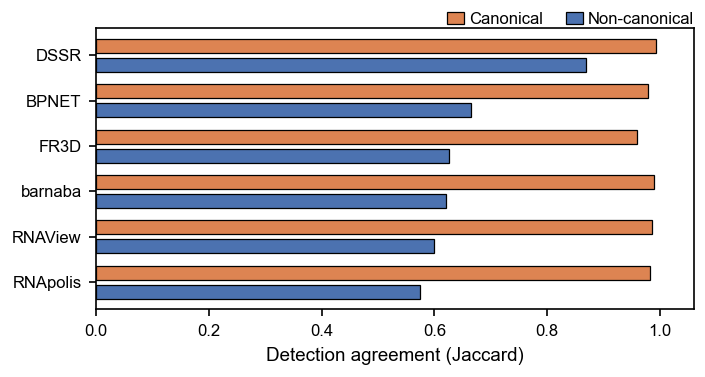

In [4]:
WATSON_CRICK = {frozenset("GC"), frozenset("AU")}


@lru_cache(maxsize=1)
def _residue_names():
    return _json("comparison/residue_names.json")


def _is_canonical(pdb, key, labels):
    names = _residue_names().get(pdb, {})
    bases = [names.get(f"{chain}|{num}|{icode}") for chain, num, icode in key]
    if None in bases or frozenset(bases) not in WATSON_CRICK:
        return False
    return any(part == "cWW" for lw in labels for part in lw.split("|"))


@lru_cache(maxsize=1)
@disk_cached
def _detection_counts():
    pairsets = _load_all_pairsets()
    counts = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        credited = fastrna_credited(tool)
        pdbs = sorted(credited.keys() & pairsets[tool].keys())
        shared, union = np.zeros((len(pdbs), 2)), np.zeros((len(pdbs), 2))
        n_ambiguous = 0
        for i, pdb in enumerate(pdbs):
            ours, theirs = credited[pdb], pairsets[tool][pdb]
            for key in ours.keys() | theirs.keys():
                labels = ours.get(key, set()) | theirs.get(key, set())
                if any("|" in lw for lw in labels):
                    n_ambiguous += 1
                    continue
                k = 0 if _is_canonical(pdb, key, labels) else 1
                union[i, k] += 1
                shared[i, k] += key in ours and key in theirs
        counts[label] = (shared, union)
        print(f"{label:9s} ambiguous pairs left out: {n_ambiguous:,}")
    return counts


@lru_cache(maxsize=1)
def fastrna_detection_by_type():
    return pd.DataFrame({label: {"canonical": s[:, 0].sum() / u[:, 0].sum(),
                                 "non-canonical": s[:, 1].sum() / u[:, 1].sum()}
                         for label, (s, u) in _detection_counts().items()}).T


@lru_cache(maxsize=None)
@disk_cached
def fastrna_detection_ci(kind):
    k = 0 if kind == "canonical" else 1
    return pd.DataFrame({label: dict(zip(("lo", "hi"), bootstrap_ci(
                             lambda w: (w @ s[:, k]) / (w @ u[:, k]), len(s))))
                         for label, (s, u) in _detection_counts().items()}).T


TOOL_ORDER = list(fastrna_detection_by_type()["non-canonical"].sort_values(ascending=False).index)
print(fastrna_detection_by_type().loc[TOOL_ORDER].round(3))
for _kind in ("canonical", "non-canonical"):
    print(_kind, "95% CI\n", fastrna_detection_ci(_kind).loc[TOOL_ORDER].round(3))


def draw_detection(ax):
    draw_split_bars(ax, fastrna_detection_by_type(),
                    {kind: fastrna_detection_ci(kind) for kind in ("canonical", "non-canonical")},
                    "Detection agreement (Jaccard)")


fig, ax = plt.subplots(figsize=(4.8, 2.6))
draw_detection(ax)
fig.tight_layout()
equalize_pair_gaps(ax)
seat_legend(ax)
save(fig, "figures/main/figure2_B_detection_agreement.png")
plt.show()

fastrna_detection_by_type().to_csv(SOURCE_DATA / "figure2_detection_agreement.csv")
for kind in ("canonical", "non-canonical"):
    fastrna_detection_ci(kind).to_csv(SOURCE_DATA / f"figure2_detection_ci_{kind}.csv")


## Panel C
Fraction of pairs both tools detect that get the same LW class as FastRNA, canonical and non-canonical pairs


          canonical  non-canonical
DSSR         0.9977         0.9561
BPNET        0.9998         0.9626
FR3D         0.9993         0.9757
barnaba      0.9948         0.7897
RNAView      0.9956         0.9138
RNApolis     0.9982         0.8771


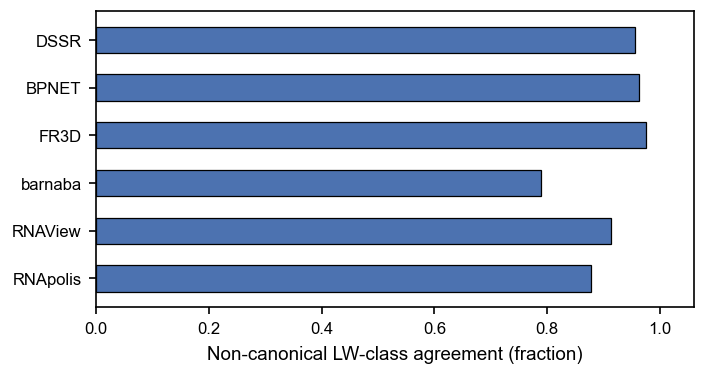

In [5]:
@lru_cache(maxsize=1)
@disk_cached
def _class_counts():
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    counts = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        ours = _single_family_units(fastrna_credited(tool))
        pdbs = sorted(pairsets["parse"].keys() & pairsets[tool].keys())
        row = {pdb: i for i, pdb in enumerate(pdbs)}
        same, shared = np.zeros((len(pdbs), 2)), np.zeros((len(pdbs), 2))
        for (pdb, key), a in ours.items():
            b = units[tool].get((pdb, key))
            if b is None or pdb not in row:
                continue
            k = 0 if _is_canonical(pdb, key, {a, b}) else 1
            shared[row[pdb], k] += 1
            same[row[pdb], k] += a == b
        counts[label] = (same, shared)
    return counts


@lru_cache(maxsize=1)
def fastrna_class_agreement():
    return pd.DataFrame({label: {"canonical": s[:, 0].sum() / n[:, 0].sum(),
                                 "non-canonical": s[:, 1].sum() / n[:, 1].sum()}
                         for label, (s, n) in _class_counts().items()}).T


@lru_cache(maxsize=None)
@disk_cached
def fastrna_class_ci(kind):
    k = 0 if kind == "canonical" else 1
    return pd.DataFrame({label: dict(zip(("lo", "hi"), bootstrap_ci(
                             lambda w: (w @ s[:, k]) / (w @ n[:, k]), len(s))))
                         for label, (s, n) in _class_counts().items()}).T


print(fastrna_class_agreement().loc[TOOL_ORDER].round(4))


def draw_classification(ax):
    v = fastrna_class_agreement()["non-canonical"].reindex(TOOL_ORDER).to_numpy(float)
    y = np.arange(len(TOOL_ORDER))
    ax.barh(y, v, 0.55, color=BLUE, edgecolor="black", linewidth=0.6)
    ax.set_yticks(y, TOOL_ORDER)
    ax.set_ylim(len(TOOL_ORDER) - 0.4, -0.6)
    ax.set_xlim(0, 1.06)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel("Non-canonical LW-class agreement (fraction)")
    finish(ax)


fig, ax = plt.subplots(figsize=(4.8, 2.6))
draw_classification(ax)
fig.tight_layout()
save(fig, "figures/main/figure2_C_classification_agreement.png")
plt.show()

fastrna_class_agreement().to_csv(SOURCE_DATA / "figure2_classification_agreement.csv")
for kind in ("canonical", "non-canonical"):
    fastrna_class_ci(kind).to_csv(SOURCE_DATA / f"figure2_classification_ci_{kind}.csv")


## Runtime helpers

In [6]:
SPEED_TOOLS = [
    ("rnapolis", "RNApolis", "#D55E00"), ("barnaba", "barnaba", "#0072B2"),
    ("fr3d", "FR3D", "#E69F00"), ("rnaview", "RNAView", "#56B4E9"),
    ("bpnet", "BPNET", "#009E73"), ("dssr", "DSSR", "#000000")]


def speedups():
    s = pd.read_csv(data_file("benchmark/runtime_direct_all/speedups.csv"))
    return s[s["baseline"] == "parse"]


N_BINS, MIN_PER_BIN = 12, 30


def size_groups(sp, n_bins=N_BINS, min_per_bin=MIN_PER_BIN):
    structs = sp[["pdb", "nucleotides"]].drop_duplicates()
    log_n = np.log10(structs["nucleotides"].to_numpy())
    edges = np.linspace(log_n.min(), log_n.max(), n_bins + 1)
    idx = np.clip(np.digitize(log_n, edges) - 1, 0, n_bins - 1)
    bins = [[k] for k in range(n_bins) if (idx == k).any()]
    count = lambda b: sum((idx == k).sum() for k in b)
    while len(bins) > 1 and min(count(b) for b in bins) < min_per_bin:
        i = min(range(len(bins)), key=lambda j: count(bins[j]))
        nbrs = [j for j in (i - 1, i + 1) if 0 <= j < len(bins)]
        j = min(nbrs, key=lambda j: count(bins[j]))
        lo, hi = sorted((i, j))
        bins[lo:hi + 1] = [bins[lo] + bins[hi]]
    to_bin = {k: g for g, b in enumerate(bins) for k in b}
    return dict(zip(structs["pdb"], (to_bin[k] for k in idx)))


## Panel A
Absolute runtime against RNA size for every tool

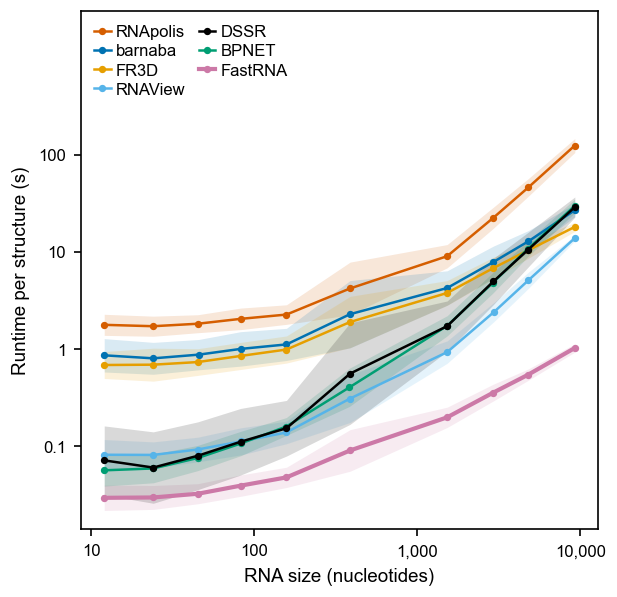

Total runtime over the 2,009 structures every tool completed (min):
FastRNA       4.3
RNAView      32.4
BPNET        63.7
DSSR         68.7
FR3D         85.3
barnaba     106.9
RNApolis    320.8


In [7]:
RUNTIME_TOOLS = [("parse", "FastRNA", "#CC79A7"), *SPEED_TOOLS]


def per_structure_runtimes():
    ps = pd.read_csv(data_file("benchmark/runtime_direct_all/per_structure.csv"))
    ps = ps[(ps["successful"] > 0) & (ps["median_seconds"] > 0)]
    return ps[ps["tool"].isin([t for t, _, _ in RUNTIME_TOOLS])]


def draw_runtime(ax):
    ps = per_structure_runtimes()
    ps = ps.assign(group=ps["pdb"].map(size_groups(speedups())),
                   log_seconds=np.log(ps["median_seconds"]))
    handles = []
    for tool, name, colour in RUNTIME_TOOLS:
        g = ps[ps["tool"] == tool].groupby("group")
        xs = (10 ** g["nucleotides"].apply(lambda n: np.median(np.log10(n)))).to_numpy()
        gmean = np.exp(g["log_seconds"].mean().to_numpy())
        gsd = np.exp(g["log_seconds"].std().to_numpy())
        lw = 2.0 if tool == "parse" else 1.2
        ax.fill_between(xs, gmean / gsd, gmean * gsd, color=colour, alpha=0.15, lw=0)
        line, = ax.plot(xs, gmean, color=colour, lw=lw, marker="o", ms=2.5, label=name,
                        zorder=4 if tool == "parse" else 3)
        handles.append((gmean[0], line))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(top=3000)
    order = [h for _, h in sorted(handles, key=lambda t: -t[0])]
    ax.legend(handles=order, loc="upper left", ncol=2, handlelength=1.0, handletextpad=0.3,
              columnspacing=0.8, labelspacing=0.25, borderaxespad=0.4, frameon=False)
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_locator(FixedLocator([0.01, 0.1, 1, 10, 100]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("RNA size (nucleotides)")
    ax.set_ylabel("Runtime per structure (s)")
    finish(ax)
    ax.set_box_aspect(1)


fig, ax = plt.subplots(figsize=(4.2, 4.2))
draw_runtime(ax)
fig.tight_layout()
save(fig, "figures/main/figure2_A_runtime_absolute.png")
plt.show()

ps = per_structure_runtimes()
common = set.intersection(*(set(ps.loc[ps["tool"] == t, "pdb"]) for t, _, _ in RUNTIME_TOOLS))
totals = pd.Series({name: ps.loc[(ps["tool"] == t) & ps["pdb"].isin(common), "median_seconds"].sum() / 60
                    for t, name, _ in RUNTIME_TOOLS}, name="total_minutes").sort_values()
print(f"Total runtime over the {len(common):,} structures every tool completed (min):")
print(totals.round(1).to_string())
totals.to_csv(SOURCE_DATA / "figure2_runtime_totals.csv")


## Combined figure


saved 6.66 x 4.69 in; at 6.73 in wide the smallest text prints at 7.00 pt, height 4.69 in


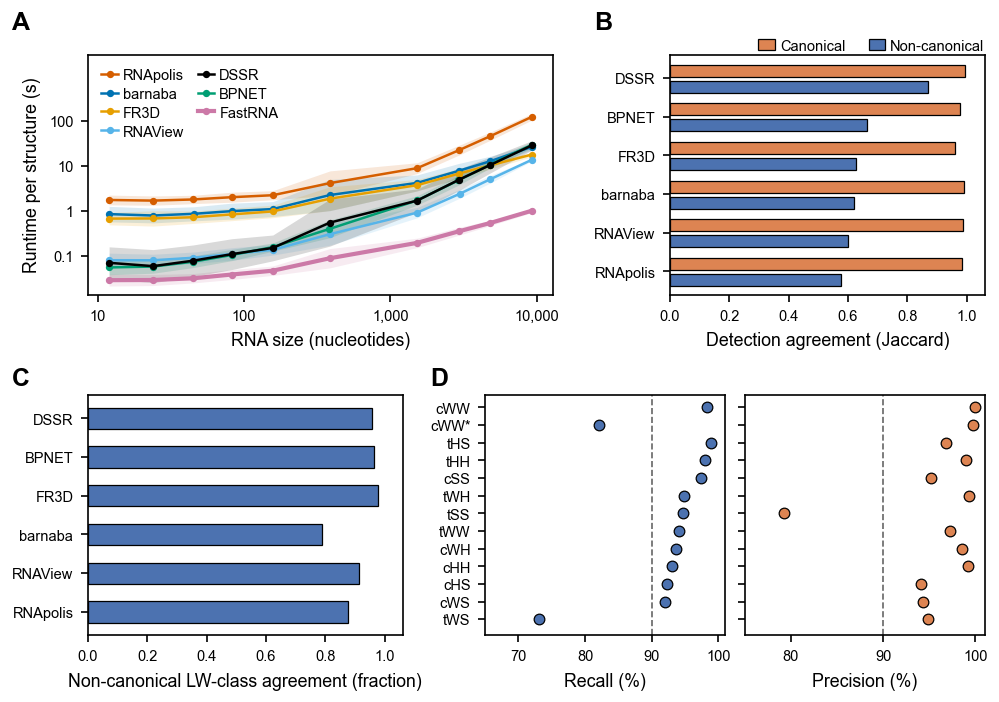

In [8]:
fig = plt.figure(figsize=(7.2, 5.6))
FIG_W, FIG_H = fig.get_size_inches()
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
SQ, D_GAP = 1.6, 0.13
LEFT, RIGHT = 0.83, 7.13
D_LABELS, B_LABELS = 0.55, 0.78
ROW1, ROW2 = 0.30, 0.30 + SQ + 0.95
D_X = RIGHT - (2 * SQ + D_GAP)
BC_W = D_X - D_LABELS - LEFT
ax_a = fig.add_axes(inch(LEFT, ROW1, RIGHT - BC_W - B_LABELS - LEFT, SQ))
ax_b = fig.add_axes(inch(RIGHT - BC_W, ROW1, BC_W, SQ))
ax_c = fig.add_axes(inch(LEFT, ROW2, BC_W, SQ))
ax_dr = fig.add_axes(inch(D_X, ROW2, SQ, SQ))
ax_dp = fig.add_axes(inch(D_X + SQ + D_GAP, ROW2, SQ, SQ))

draw_runtime(ax_a)
draw_detection(ax_b)
draw_classification(ax_c)
draw_recall_precision(ax_dr, ax_dp)
for ax in (ax_a, ax_b, ax_c):
    ax.set_box_aspect(None)
RSC_W = 6.73
fig.canvas.draw()
over = fig.get_tightbbox(fig.canvas.get_renderer()).width - (RSC_W - 2 * 0.08)
if over > 0:
    fig_w = fig.get_size_inches()[0]
    for ax in (ax_b, ax_c):
        q = ax.get_position()
        ax.set_box_aspect(None)
        ax.set_position([q.x0, q.y0, q.width - over / fig_w, q.height], which="both")
    for ax in (ax_dr, ax_dp):
        q = ax.get_position()
        ax.set_position([q.x0 - over / fig_w, q.y0, q.width, q.height], which="both")


ROW_GAP_IN = 0.25


def restack_rows(fig, rows, gap_in=ROW_GAP_IN, margin_in=0.05, extras=()):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    deltas, cursor = [], margin_in
    for top, bot in zip(tops, bots):
        deltas.append(cursor - top)
        cursor += bot - top + gap_in
    H2 = cursor - gap_in + margin_in
    for a, i in extras:
        H2 = max(H2, H - a.get_position(original=True).y0 * H + deltas[i] + margin_in)
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2

    def move(a, d):
        p = a.get_position(original=True)
        a.set_position([p.x0, conv(p.y0, d), p.width, p.height * H / H2], which="both")

    for i, row in enumerate(rows):
        for a in row:
            move(a, deltas[i])
    for a, i in extras:
        move(a, deltas[i])
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))
    for art in fig.artists:
        if hasattr(art, "_posA_posB") and art._posA_posB:
            (xa, ya), (xb, yb) = art._posA_posB
            d = deltas[row_of(H - ya * H)]
            art.set_positions((xa, conv(ya, d)), (xb, conv(yb, d)))

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)
equalize_pair_gaps(ax_b)
seat_legend(ax_b)

fig.canvas.draw()
inv = fig.transFigure.inverted()
renderer = fig.canvas.get_renderer()
bbox = lambda ax: ax.get_tightbbox(renderer).transformed(inv)
columns = {"A": min(bbox(ax_a).x0, bbox(ax_c).x0), "C": min(bbox(ax_a).x0, bbox(ax_c).x0),
           "B": bbox(ax_b).x0, "D": bbox(ax_dr).x0}
row_top = {"AB": max(bbox(a).y1 for a in (ax_a, ax_b)),
           "CD": max(bbox(a).y1 for a in (ax_c, ax_dr, ax_dp))}
for s in "ABCD":
    y = row_top["AB" if s in "AB" else "CD"] + 0.03 / fig.get_size_inches()[1]
    fig.text(columns[s], y, s, fontsize=LETTER_PT, fontweight="bold", ha="left", va="bottom")

restack_rows(fig, [[ax_a, ax_b], [ax_c, ax_dr, ax_dp]], gap_in=0.12)

def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

save(fig, "figures/main/figure2.png")
plt.show()